# Forecasting the Dec 2022 – Jan 2023 West Coast Flood with SFNO and PrecipitationAFNO v2 vs ERA5 — a lead-time sweep

The New Year **atmospheric river** that flooded the Sacramento area on **Dec 31 2022 – Jan 1 2023** opened the 2022–2023 West Coast flood season. This notebook asks how far ahead an AI weather model could see it. Using NVIDIA **Earth2Studio**, **SFNO** (a global forecast model trained on ERA5) is run three times, initialized **3, 7 and 10 days before the event** (2022-12-28, 2022-12-24 and 2022-12-21, all 00Z) from **ERA5** fields fetched from the Copernicus Climate Data Store. SFNO has no precipitation output, so a second network, **PrecipitationAFNO v2**, reads SFNO's fields at every 6-hour step and returns the 6-hour accumulated **precipitation**, which is compared with ERA5 precipitation over the West Coast. You will see per-day precipitation tables, event-total maps by lead time, a skill table by lead time, and event totals at the flood locations.

> **Measured on an NVIDIA L40:** 2 min runtime · 17.4 GiB peak GPU memory.

**Contents**
1. Load SFNO and the precipitation model
2. Run the lead-time sweep — three SFNO + PrecipitationAFNO v2 forecasts of the same flood
3. Load the forecasts and fetch ERA5 precipitation truth
4. Helpers: regional cropping, longitude conversion, area-weighting, error metrics
5. Per-day accumulated-precipitation tables — one per lead time
6. Event-total precipitation maps by lead time (a locator map for the five locations; 6b: skill by lead time)
7. Event-total precipitation by location and lead time

The notebook ends with a **Summary** of what each figure and table answers.

**Lead-time experiment.** The flood is a *fixed target*. We forecast it from **three different lead times — 3, 7, and 10 days** — by initializing three separate SFNO runs, each followed by the precipitation model:

| lead | init (00Z) | forecast covers up to |
|------|------------|-----------------------|
| 3 d  | 2022-12-28 | 2023-01-02 00Z |
| 7 d  | 2022-12-24 | 2023-01-02 00Z |
| 10 d | 2022-12-21 | 2023-01-02 00Z |

All three are valid over the same Dec 31 – Jan 1 window, so each is verified against the **same ERA5 truth**. The question is how far ahead the model could see this atmospheric river: the tables and maps put the 3-, 7- and 10-day forecasts next to the same ERA5 totals.

**Precipitation accumulation.** PrecipitationAFNO v2's output id is **`tp06`** — *6-hour accumulated* total precipitation, returned in metres. earth2studio documents the output stamped *t* as the precipitation of the *following* 6 hours, [*t*, *t* + 6 h], so the output at lead 0 is the first 6 hours of the forecast and nothing is dropped. A UTC day (00Z to 24Z) is the sum of the four outputs stamped 00Z, 06Z, 12Z and 18Z of that day, and the last output needed is the 18Z one of the last event day. ERA5's `total_precipitation` is *hourly accumulation* (metres), stamped at the *end* of each hour; shifting the ERA5 stamps back one hour makes a daily sum cover the same period (24 hourly values stamped 01Z through the next day's 00Z). Both sides are converted × 1000 → mm and summed into UTC-day totals (§3). Because we compare **accumulated totals**, the comparison avoids the sampling caveat of the daily maxima in `HeatWaves.ipynb`.

**Truth caveat.** ERA5 precipitation is itself **model-derived**: it comes from the reanalysis forecast model, constrained by assimilated observations, and not from rain gauges or radar. The forecast precipitation is model-derived too: it is a diagnostic network applied to SFNO's fields, not a native SFNO output. The skill numbers here measure agreement with ERA5, not with observed rainfall. ERA5's 0.25° grid also smooths local extremes, so values at a single grid cell are not gauge values.

In [1]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc
import shutil
import warnings
from collections import OrderedDict
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import torch
import xarray as xr
from matplotlib.colors import BoundaryNorm

from earth2studio.data import CDS
from earth2studio.io import ZarrBackend
from earth2studio.models.dx import PrecipitationAFNOv2
from earth2studio.models.px import SFNO
from earth2studio.run import diagnostic
from metrics import event_total_error, skill_row

warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__)


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


def map_colorbar(fig, ax, mappable, label=None, orientation="vertical", **kwargs):
    '''Colorbar attached to `ax` that is exactly as long as the drawn map (never longer).

    fig.colorbar(..., ax=ax, shrink=...) sizes the bar from the axes box before a map's fixed
    aspect ratio is applied, so on wide maps the bar comes out taller than the map.'''
    side, pad = ("right", 0.1) if orientation == "vertical" else ("bottom", 0.35)
    cax = make_axes_locatable(ax).append_axes(side, size="4%", pad=pad, axes_class=plt.Axes)
    return fig.colorbar(mappable, cax=cax, orientation=orientation, label=label, **kwargs)


PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PROJECT / "data"
FIG_DIR = PROJECT / "figures"
for d in (DATA_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

PRECIP_CMAP = plt.cm.rainbow_r  # house style: red = little rain, blue-purple = a lot
FC_LABEL = "SFNO+precip"        # short name of the forecast in table headers, legends and panel titles

# --- Event & lead-time configuration ---
# Anchor event: the New Year atmospheric river (Sacramento-area flooding).
EVENT_START = np.datetime64("2022-12-31")           # AR core day 1
EVENT_END   = np.datetime64("2023-01-01")           # AR core day 2
EVENT_DAYS  = np.array([EVENT_START, EVENT_END])     # days summed for the "event total"
# The output stamped t covers [t, t+6h], so the last output needed is the 18Z one of the last event day.
LAST_STAMP  = EVENT_END + np.timedelta64(18, "h")

LEAD_DAYS = [3, 7, 10]                                # days before the event we initialize
def init_for_lead(lead):
    return EVENT_START - np.timedelta64(int(lead), "D")
def nsteps_for_init(init):
    return int((LAST_STAMP - np.datetime64(init)) / np.timedelta64(6, "h"))

PRECIP_VAR = "tp06"   # PrecipitationAFNOv2 output id: 6-hour ACCUMULATED total precip (m). Verified in section 1.

# Region (used only to crop the maps). lon given in BOTH 0-360 (native) and -180..180 (plotting).
REGIONS = {
    "WEST_COAST": dict(lat=(32, 47), lon360=(232, 247), lon180=(-128, -113)),
}

# Flood-affected locations: name -> (lat, lon in -180..180). Cosumnes R. @ Wilton is where the
# New Year AR breached levees and flooded Highway 99 (~Dec 31 2022).
LOCATIONS = {
    "San Francisco":        (37.77, -122.42),
    "Sacramento":           (38.58, -121.49),
    "Oakland":              (37.80, -122.27),
    "Santa Rosa":           (38.44, -122.71),
    "Cosumnes R. (Wilton)": (38.40, -121.24),
}
# short codes for compact table / plot labels
SHORT = {"San Francisco": "SF", "Sacramento": "SAC", "Oakland": "OAK",
         "Santa Rosa": "SRO", "Cosumnes R. (Wilton)": "COS"}

for L in LEAD_DAYS:
    init = init_for_lead(L)
    print(f"lead {L:2d} d  |  init {str(init)[:10]} 00Z  |  "
          f"{nsteps_for_init(init)} steps x 6h  ->  last output stamped "
          f"{np.datetime_as_string(LAST_STAMP, unit='h').replace('T', ' ')}Z")

device: cuda | torch 2.13.0+cu132
lead  3 d  |  init 2022-12-28 00Z  |  19 steps x 6h  ->  last output stamped 2023-01-01 18Z
lead  7 d  |  init 2022-12-24 00Z  |  35 steps x 6h  ->  last output stamped 2023-01-01 18Z
lead 10 d  |  init 2022-12-21 00Z  |  47 steps x 6h  ->  last output stamped 2023-01-01 18Z


## 1 · Load SFNO and the precipitation model

**SFNO** is a global weather forecast model trained on ERA5. It steps the atmosphere forward in 6-hour steps on a 0.25° grid and predicts 73 variables (winds, temperature, humidity and geopotential on 13 pressure levels, plus surface fields). Precipitation is not one of them. **`PrecipitationAFNOv2`** is a second, separate network that reads 20 of SFNO's fields at each step and returns the precipitation accumulated over 6 hours. earth2studio itself marks `PrecipitationAFNOv2` as planned for deprecation in a future release, so if you pin a newer earth2studio expect this part to change. The precipitation totals in this notebook are therefore a model-derived estimate computed from SFNO's atmospheric state, and they are compared with ERA5, not with rain gauges. The cell below loads both models, prints what each one reads and returns, and checks that the precipitation variable used later (`tp06`) is an output of the precipitation model.

In [2]:
sfno = SFNO.load_model(SFNO.load_default_package()).to(DEVICE)
precip = PrecipitationAFNOv2.load_model(PrecipitationAFNOv2.load_default_package()).to(DEVICE)

sfno_in = sfno.input_coords()
precip_in = precip.input_coords()
precip_out_vars = list(map(str, precip.output_coords(precip_in)["variable"]))

print("SFNO loaded | n inputs:", len(sfno_in["variable"]),
      "| grid:", len(sfno_in["lat"]), "x", len(sfno_in["lon"]))
print("PrecipitationAFNOv2 loaded | reads", len(precip_in["variable"]), "SFNO variables:",
      ", ".join(map(str, precip_in["variable"])))
print("precipitation model output variable(s):", precip_out_vars, "| PRECIP_VAR:", PRECIP_VAR)

assert PRECIP_VAR in precip_out_vars, f"{PRECIP_VAR} is not a PrecipitationAFNOv2 output: {precip_out_vars}"
assert set(map(str, precip_in["variable"])) <= set(map(str, sfno_in["variable"])), \
    "PrecipitationAFNOv2 reads variables that SFNO does not provide"


SFNO loaded | n inputs: 73 | grid: 721 x 1440
PrecipitationAFNOv2 loaded | reads 20 SFNO variables: u10m, v10m, t2m, sp, msl, tcwv, u500, u850, u1000, v500, v850, v1000, z50, z500, z850, z1000, t500, t850, q500, q850
precipitation model output variable(s): ['tp06'] | PRECIP_VAR: tp06


## 2 · Run the lead-time sweep — three SFNO + PrecipitationAFNO v2 forecasts of the same flood

`run_forecast()` drives SFNO and the precipitation model through earth2studio's `diagnostic()` pipeline from an ERA5 initial state. At each 6-hour output time `PrecipitationAFNOv2` turns the atmospheric state (the ERA5 initial state at lead 0, then SFNO's forecast after each 6-hour step) into the precipitation of the following 6 hours; only that precipitation (`tp06`) is written, as one Zarr store per init date, including the output at lead 0. The output variable is folded into the cache filename (`sfno_precip_forecast_init<date>_tp06_<n>steps.zarr`) so each variable's runs get their own cache. We loop it over the three init dates with the two model instances loaded in §1, then release both from the GPU. Each store is written to `<name>.zarr.partial` and renamed to `<name>.zarr` only when its run completes, so an interrupted run (a failed cell or a killed kernel) never leaves a finished-looking store under the final name. The one exception is replacing an existing store with `overwrite=True`, which deletes the old store just before the rename; the cells below never pass it. **The first run of each init downloads the 73-variable ERA5 initial state SFNO needs from the CDS (slow), then caches it** — re-runs are fast. If you re-run this cell after the models have been released and a forecast has to be recomputed, run §1 again first.

In [3]:
def run_forecast(init_time, nsteps, variables, overwrite=False):
    '''Global SFNO + PrecipitationAFNO v2 forecast from an ERA5 init -> path to a Zarr store holding only `variables`.
    Cache key includes the (first) output variable and the number of steps, so changing either gets its own cache.'''
    tag  = np.datetime_as_string(np.datetime64(init_time), unit="D").replace("-", "")
    vtag = str(np.asarray(variables)[0])
    out_path = DATA_DIR / f"sfno_precip_forecast_init{tag}_{vtag}_{nsteps}steps.zarr"
    if out_path.exists() and not overwrite:
        print("using cached forecast:", out_path)
        return out_path
    # ZarrBackend allocates the whole lead axis up front, so a store left by a killed kernel looks complete.
    # Write to <name>.partial and rename it only after the run finishes; the cache check above sees only <name>.
    partial = out_path.with_name(out_path.name + ".partial")
    shutil.rmtree(partial, ignore_errors=True)       # stale partial store from an interrupted run
    try:
        diagnostic(
            time=[np.datetime64(init_time)],
            nsteps=nsteps,
            prognostic=sfno,
            diagnostic=precip,
            data=CDS(cache=True),
            io=ZarrBackend(str(partial), backend_kwargs={"overwrite": True}),
            output_coords=OrderedDict({"variable": np.asarray(variables)}),
            device=DEVICE,
        )
    except BaseException:
        shutil.rmtree(partial, ignore_errors=True)   # never leave a half-written store behind
        raise
    shutil.rmtree(out_path, ignore_errors=True)      # overwrite=True: replace the old finished store
    partial.rename(out_path)
    return out_path

fc_paths = {}
try:
    for L in LEAD_DAYS:
        init = init_for_lead(L)
        print(f"\n--- lead {L} d  (init {str(init)[:10]} 00Z, {nsteps_for_init(init)} steps) ---")
        fc_paths[L] = run_forecast(init, nsteps=nsteps_for_init(init),
                                   variables=np.array([PRECIP_VAR]))
finally:
    # One SFNO and one PrecipitationAFNOv2 instance serve all three runs, so release both (and cached CUDA memory) once the sweep ends.
    free_gpu("sfno", "precip")

print("\nforecasts:")
for L, p in fc_paths.items():
    print(f"  lead {L:2d} d -> {p}")


--- lead 3 d  (init 2022-12-28 00Z, 19 steps) ---
2026-11-01 06:40:49.064 | INFO     | earth2studio.run:diagnostic:238 - Running diagnostic workflow!
2026-11-01 06:40:49.064 | INFO     | earth2studio.run:diagnostic:244 - Inference device: cuda
2026-11-01 06:40:49.088 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 10m_u_component_of_wind at 2022-12-28 00:00:00 with 1 levels
2026-11-01 06:40:49.088 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 10m_v_component_of_wind at 2022-12-28 00:00:00 with 1 levels
2026-11-01 06:40:49.088 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 100m_u_component_of_wind at 2022-12-28 00:00:00 with 1 levels
2026-11-01 06:40:49.088 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 100m_v_component_of_wind at 2022-12-28 00:00:00 with 1 levels
2026-11-01 06:40:49.088 | DEBUG    | eart

## 3 · Load the forecasts and fetch ERA5 precipitation truth

We read each forecast's `tp06`, check that the lead axis is regular 6-hour steps starting at 0, attach a **valid-time** axis (`init + lead`, the start of each 6-hour window), convert m → mm, and sum the 6-hourly accumulations into **daily totals**. earth2studio documents the output stamped *t* as the precipitation of the following 6 hours, so lead 0 is the first 6 hours of the forecast and nothing is dropped; a UTC day is the sum of the four outputs stamped 00Z, 06Z, 12Z and 18Z, and the sum fails loudly if a day does not have exactly four. ERA5 truth is pulled from the CDS as **hourly** `total_precipitation` over a West-Coast area subset, shifted back one hour (ERA5 stamps each hour at its end) and summed into daily totals (mm) that cover the same 00Z to 24Z period. Both sit on the same 0.25° lattice, so no regridding is needed (`to_region_pair` in §4 matches the coordinates). Remember that ERA5 precipitation is itself model-derived.

In [4]:
def load_forecast_precip(path, init_time, var=PRECIP_VAR):
    '''Open a forecast Zarr -> 6-hourly ACCUMULATED precip (valid_time, lat, lon) in mm/6h.

    PrecipitationAFNOv2 returns metres per 6 h. earth2studio documents the output stamped t as the
    precipitation of the FOLLOWING 6 h, [t, t+6h], so lead 0 is the first 6 h of the forecast and nothing
    is dropped. valid_time (init + lead) is the START of each 6 h window.'''
    ds = xr.open_zarr(str(path))
    da = ds[var]
    for d in ("batch", "time"):                       # squeeze singleton init dims
        if d in da.dims:
            da = da.isel({d: 0}, drop=True)
    lead = da["lead_time"].values
    assert lead[0] == np.timedelta64(0, "h") and (np.diff(lead) == np.timedelta64(6, "h")).all(), \
        f"expected lead times 0 h, 6 h, 12 h, ... in regular 6 h steps, got {lead[:4].astype('timedelta64[h]').astype(int).tolist()} h ..."
    valid = np.datetime64(init_time) + da["lead_time"].values
    da = da.assign_coords(lead_time=valid).rename(lead_time="valid_time")
    da = (da * 1000.0).clip(min=0.0)                  # m -> mm, guard tiny negatives
    return da.assign_attrs(units="mm")

def daily_total(da, time_name="valid_time"):
    '''6-hourly precip -> daily TOTAL (mm/day) for each UTC day (00Z to 24Z); renames the day axis to 'day'.

    The output stamped t covers [t, t+6h], so calendar day D is the sum of the four outputs stamped
    D 00Z, 06Z, 12Z and 18Z: no shift of the stamps is needed. A day with fewer than four outputs
    (a partial day) raises instead of returning a short total.'''
    ids, counts = np.unique(da[time_name].values.astype("datetime64[D]"), return_counts=True)
    assert (counts == 4).all(), ("every UTC day must add exactly four 6 h outputs (00Z, 06Z, 12Z, 18Z); "
                                 f"got {dict(zip(ids.astype(str), counts.tolist()))}. If a cached forecast made with a different step count is being reused, delete its .zarr folder in data/ and run again.")
    out = da.resample({time_name: "1D"}).sum()
    return out.rename({time_name: "day"})

# Forecast daily-total precip, one field per lead time
fc_daily = {}
for L in LEAD_DAYS:
    da = load_forecast_precip(fc_paths[L], init_for_lead(L))
    fc_daily[L] = daily_total(da)
    d0, d1 = fc_daily[L]["day"].values[[0, -1]]
    print(f"lead {L:2d} d forecast daily precip: {dict(fc_daily[L].sizes)}  "
          f"{str(d0)[:10]} -> {str(d1)[:10]}")

WC = REGIONS["WEST_COAST"]
# ERA5 area subset (1 deg wider than the plot bbox): [North, West, South, East] in -180..180
ERA5_AREA = [WC["lat"][1] + 1, WC["lon180"][0] - 1, WC["lat"][0] - 1, WC["lon180"][1] + 1]

def fetch_era5_precip(days, area, cache_path):
    '''ERA5 daily-total precip (mm) over `area` for the given UTC days: hourly
    total_precipitation summed per day over (00Z, 24Z]. One batched CDS request per month, cached.'''
    import hashlib
    cache_path = Path(cache_path)
    days_wanted = [np.datetime64(d, "D") for d in days]
    if cache_path.exists():
        cached = xr.open_dataarray(cache_path)
        north, west, south, east = area
        covers_days = set(days_wanted) <= set(cached["day"].values.astype("datetime64[D]"))
        covers_area = (float(cached["lat"].min()) <= south + 0.25 and float(cached["lat"].max()) >= north - 0.25
                       and float(cached["lon"].min()) <= west % 360 + 0.25 and float(cached["lon"].max()) >= east % 360 - 0.25)
        if covers_days and covers_area:
            return cached
        print("cached ERA5 file does not cover the requested days or area; downloading again")
        cached.close()
    import cdsapi
    # Also request the day after the last wanted day: its 00Z hour closes the final (00Z, 24Z] window.
    days = days_wanted + [max(days_wanted) + np.timedelta64(1, "D")]
    by_month = {}
    for d in days:
        ym = (str(d)[:4], str(d)[5:7])
        by_month.setdefault(ym, set()).add(str(d)[8:10])
    client = cdsapi.Client()
    parts = []
    for (yr, mo), dnums in sorted(by_month.items()):
        # The file name carries a short hash of the days and area, so a changed request never reuses a stale file.
        key = hashlib.md5(repr((sorted(dnums), list(area))).encode()).hexdigest()[:8]
        tmp = cache_path.with_name(f"_era5_tp_{yr}{mo}_{key}.nc")
        if not tmp.exists():
            request = {"product_type": "reanalysis", "variable": "total_precipitation",
                       "year": yr, "month": mo, "day": sorted(dnums),
                       "time": [f"{h:02d}:00" for h in range(24)],
                       "area": area}
            try:
                client.retrieve("reanalysis-era5-single-levels",
                                {**request, "data_format": "netcdf", "download_format": "unarchived"},
                                str(tmp))
            except Exception:
                # Older cdsapi / CDS deployments only know the legacy "format" key.
                client.retrieve("reanalysis-era5-single-levels", {**request, "format": "netcdf"}, str(tmp))
        d = xr.open_dataset(tmp)["tp"].drop_vars(["number", "expver"], errors="ignore")
        d = d.rename({"latitude": "lat", "longitude": "lon"})
        tname = "valid_time" if "valid_time" in d.dims else ("time" if "time" in d.dims else list(d.dims)[0])
        parts.append(d.rename({tname: "valid_time"}))
    da = xr.concat(parts, dim="valid_time") if len(parts) > 1 else parts[0]
    da = da.assign_coords(lon=(da["lon"] % 360)).sortby("lon")   # -> 0-360, match the model grid
    da = (da * 1000.0).clip(min=0.0)                              # m -> mm
    # ERA5 hourly values are stamped at the END of the accumulation hour; shift back 1 h so a
    # calendar-day sum covers 00Z to 24Z, the same period as the model's four 6-h windows.
    da = da.assign_coords(valid_time=da["valid_time"] - np.timedelta64(1, "h"))
    da = da.resample(valid_time="1D").sum().rename(valid_time="day")
    da = da.sel(day=np.array(days_wanted, dtype="datetime64[ns]"))
    da.name = "tp"
    da = da.assign_attrs(units="mm")
    da.to_netcdf(cache_path)
    return da

# union of all forecast days across leads (the 10-day lead spans the most)
all_days = np.unique(np.concatenate([fc_daily[L]["day"].values for L in LEAD_DAYS]))
era5_daily = fetch_era5_precip(all_days, ERA5_AREA, DATA_DIR / "era5_tp_westcoast_utcday.nc")
print("ERA5 daily precip:", dict(era5_daily.sizes),
      "|", str(era5_daily["day"].values[0])[:10], "->", str(era5_daily["day"].values[-1])[:10])

lead  3 d forecast daily precip: {'day': 5, 'lat': 720, 'lon': 1440}  2022-12-28 -> 2023-01-01
lead  7 d forecast daily precip: {'day': 9, 'lat': 720, 'lon': 1440}  2022-12-24 -> 2023-01-01
lead 10 d forecast daily precip: {'day': 12, 'lat': 720, 'lon': 1440}  2022-12-21 -> 2023-01-01


2026-11-01 06:41:59,701 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-01 06:42:00,465 INFO Request ID is 6d69856e-83e2-4ace-b771-bd6af184a7ed
2026-11-01 06:42:00,660 INFO status has been updated to successful
2026-11-01 06:42:05,175 INFO Request ID is b6742ff6-3774-4969-84fa-2584120ef1f0
2026-11-01 06:42:05,367 INFO status has been updated to successful


ERA5 daily precip: {'day': 12, 'lat': 69, 'lon': 69} | 2022-12-21 -> 2023-01-01


## 4 · Helpers: regional cropping, longitude conversion, area-weighting, error metrics

The maps and tables below all work on the same West Coast crop, so the cropping helpers live in one place. `crop_bbox` and `to_180` are the same helpers `HeatWaves.ipynb` uses; `at_point` and `to_region_pair` are small additions for the precipitation tables and for grid- and day-matching each lead's forecast to ERA5. The area-weighted error metrics (`skill_row`, `event_total_error`) come from `metrics.py` next to this notebook.

In [5]:
def crop_bbox(da, lat_range, lon360_range, lat_name="lat", lon_name="lon"):
    '''Slice a DataArray (lon in 0-360, lat descending) to a bbox given in 0-360 lon.'''
    lo_lat, hi_lat = min(lat_range), max(lat_range)
    da = da.sel({lat_name: slice(hi_lat, lo_lat)})         # lat is descending
    lo_lon, hi_lon = lon360_range
    if lo_lon <= hi_lon:
        return da.sel({lon_name: slice(lo_lon, hi_lon)})
    lon = da[lon_name]
    return da.sel({lon_name: lon[(lon >= lo_lon) | (lon <= hi_lon)]})   # dateline wrap

def to_180(da, lon_name="lon"):
    '''Convert lon 0-360 -> -180..180 and sort (for cartopy plotting).'''
    da = da.assign_coords({lon_name: (((da[lon_name] + 180) % 360) - 180)})
    return da.sortby(lon_name)

def at_point(da, lat, lon):
    '''EXACT value at the single 0.25 deg grid cell nearest a point (lon in -180..180).
    No averaging - this is the model's grid-box value containing the location.'''
    return da.sel(lat=lat, lon=lon % 360, method="nearest")

def to_region_pair(fc_field, era5_field, region):
    '''Crop forecast + ERA5 daily fields to a region, put ERA5 on the forecast grid, keep common days.
    Used only for the spatial maps.'''
    info = REGIONS[region]
    a = crop_bbox(fc_field, info["lat"], info["lon360"])
    e = crop_bbox(era5_field, info["lat"], info["lon360"])
    e = e.reindex(lat=a["lat"], lon=a["lon"], method="nearest")     # exact same 0.25 deg grid
    common = np.intersect1d(a["day"].values, e["day"].values)
    return a.sel(day=common), e.sel(day=common)

# West Coast crops for the maps: fc_wc[L] and the matching era5_wc[L] (same grid; days = lead L)
fc_wc, era5_wc = {}, {}
for L in LEAD_DAYS:
    fc_wc[L], era5_wc[L] = to_region_pair(fc_daily[L], era5_daily, "WEST_COAST")
print("West Coast map grid:", dict(fc_wc[LEAD_DAYS[0]].sizes))

West Coast map grid: {'day': 5, 'lat': 61, 'lon': 61}


## 5 · Per-day accumulated-precipitation tables — one per lead time

For each lead time, a table of **total precipitation accumulated per day** (mm) at each affected
location — the four cities plus the **Cosumnes River @ Wilton** — read from the **exact nearest
0.25° grid cell** (no spatial averaging; this is the model's grid-box value containing the site, not a
rain-gauge point). Columns are grouped by location into SFNO+precip (SFNO + PrecipitationAFNO v2) vs ERA5, and the event days
(Dec 31 + Jan 1) are summed in the bottom **EVENT TOTAL** row.

In [6]:
try:
    from IPython.display import display
except Exception:
    display = print

for L in LEAD_DAYS:
    a = fc_daily[L]                   # global forecast daily totals for this lead
    days = a["day"].values
    era5_days = set(era5_daily["day"].values)
    cols = {}
    for name, (lat, lon) in LOCATIONS.items():
        code = SHORT[name]
        a_loc = at_point(a, lat, lon)
        e_loc = at_point(era5_daily, lat, lon)
        cols[(code, FC_LABEL)] = [round(float(a_loc.sel(day=d)), 1) for d in days]
        cols[(code, "ERA5")] = [round(float(e_loc.sel(day=d)), 1) if d in era5_days else np.nan
                                for d in days]
    df = pd.DataFrame(cols, index=[str(d)[:10] for d in days])
    df.columns = pd.MultiIndex.from_tuples(df.columns, names=["location", "source"])
    df.index.name = "valid day (UTC)"

    # event-total row (Dec 31 + Jan 1)
    evmask = np.isin(np.array(df.index), np.array([str(x)[:10] for x in EVENT_DAYS]))
    ev = df[evmask].sum(axis=0).round(1)
    ev.name = "EVENT TOTAL"
    df_show = pd.concat([df, ev.to_frame().T])

    print(f"\n===== Lead {L} d  |  init {str(init_for_lead(L))[:10]} 00Z  |  "
          f"daily TOTAL precip (mm), exact grid cell per location =====")
    display(df_show)


===== Lead 3 d  |  init 2022-12-28 00Z  |  daily TOTAL precip (mm), exact grid cell per location =====


location             SF               SAC               OAK               SRO  \
source      SFNO+precip  ERA5 SFNO+precip  ERA5 SFNO+precip  ERA5 SFNO+precip   
2022-12-28          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-29          0.7   5.5         0.4   5.3         0.3   3.2         1.3   
2022-12-30          7.4  11.2        14.5  31.0         3.1   6.7        12.4   
2022-12-31         12.2  81.9        15.0  58.0         9.6  84.2        18.3   
2023-01-01          0.2   3.9         0.5  16.2         0.2   5.5         0.0   
EVENT TOTAL        12.4  85.8        15.5  74.2         9.8  89.7        18.3   

location                  COS        
source       ERA5 SFNO+precip  ERA5  
2022-12-28    0.0         0.1   0.1  
2022-12-29    6.8         0.3   5.4  
2022-12-30   16.2        17.7  33.2  
2022-12-31   35.7        21.1  76.8  
2023-01-01    1.1         2.0  21.3  
EVENT TOTAL  36.8        23.1  98.1


===== Lead 7 d  |  init 2022-12-24 00Z  |  daily TOTAL precip (mm), exact grid cell per location =====


location             SF               SAC               OAK               SRO  \
source      SFNO+precip  ERA5 SFNO+precip  ERA5 SFNO+precip  ERA5 SFNO+precip   
2022-12-24          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-25          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-26          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-27         19.1  29.0        22.8  37.8        12.7  24.1        30.0   
2022-12-28          0.2   0.0         0.1   0.0         0.1   0.0         0.1   
2022-12-29          0.9   5.5         2.3   5.3         0.4   3.2         2.4   
2022-12-30          4.1  11.2         4.5  31.0         1.4   6.7         5.6   
2022-12-31          6.7  81.9         7.9  58.0         4.8  84.2        11.8   
2023-01-01          0.0   3.9         0.0  16.2         0.0   5.5         0.0   
EVENT TOTAL         6.7  85.8         7.9  74.2         4.8  89.7        11.8   

location                  COS        
source       ERA5 SFNO+precip  ERA5  
2022-12-24    0.0         0.0   0.0  
2022-12-25    0.0         0.0   0.0  
2022-12-26    0.3         0.0   0.0  
2022-12-27   36.8        23.1  44.5  
2022-12-28    0.0         0.4   0.1  
2022-12-29    6.8         2.2   5.4  
2022-12-30   16.2         5.0  33.2  
2022-12-31   35.7        10.0  76.8  
2023-01-01    1.1         0.2  21.3  
EVENT TOTAL  36.8        10.2  98.1


===== Lead 10 d  |  init 2022-12-21 00Z  |  daily TOTAL precip (mm), exact grid cell per location =====


location             SF               SAC               OAK               SRO  \
source      SFNO+precip  ERA5 SFNO+precip  ERA5 SFNO+precip  ERA5 SFNO+precip   
2022-12-21          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-22          0.1   0.0         0.0   0.0         0.0   0.0         0.1   
2022-12-23          0.6   0.8         0.5   0.6         0.1   0.9         0.5   
2022-12-24          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-25          0.0   0.0         0.0   0.0         0.0   0.0         0.0   
2022-12-26          3.0   0.0         1.5   0.0         1.4   0.0         7.3   
2022-12-27         21.4  29.0        25.3  37.8        16.9  24.1        23.4   
2022-12-28          8.4   0.0        10.0   0.0         5.4   0.0         7.6   
2022-12-29         12.2   5.5        10.7   5.3         9.1   3.2         7.3   
2022-12-30          0.1  11.2         0.0  31.0         0.0   6.7         0.0   
2022-12-31          2.6  81.9         1.8  58.0         1.3  84.2         4.5   
2023-01-01          0.0   3.9         0.0  16.2         0.0   5.5         0.0   
EVENT TOTAL         2.6  85.8         1.8  74.2         1.3  89.7         4.5   

location                  COS        
source       ERA5 SFNO+precip  ERA5  
2022-12-21    0.0         0.0   0.0  
2022-12-22    0.0         0.0   0.0  
2022-12-23    1.3         0.4   0.1  
2022-12-24    0.0         0.0   0.0  
2022-12-25    0.0         0.0   0.0  
2022-12-26    0.3         1.1   0.0  
2022-12-27   36.8        28.4  44.5  
2022-12-28    0.0        15.3   0.1  
2022-12-29    6.8        17.9   5.4  
2022-12-30   16.2         0.2  33.2  
2022-12-31   35.7         2.9  76.8  
2023-01-01    1.1         0.0  21.3  
EVENT TOTAL  36.8         2.9  98.1

## 6 · Event-total precipitation maps by lead time

The maps show where the atmospheric river's rain fell (Dec 31 2022 + Jan 1 2023) and how the forecast changes with lead time. A locator map comes first, so that the nine-panel grid after it can mark the five flood locations with small unlabeled markers and leave the rain visible.

### Where the five locations are

The four cities and the Cosumnes River site sit within about a degree and a half of each other around San Francisco Bay and the Sacramento Valley, too close together to label legibly on the precipitation maps. This map shows only that region, with a name for each location (the short codes used in the tables are in brackets).

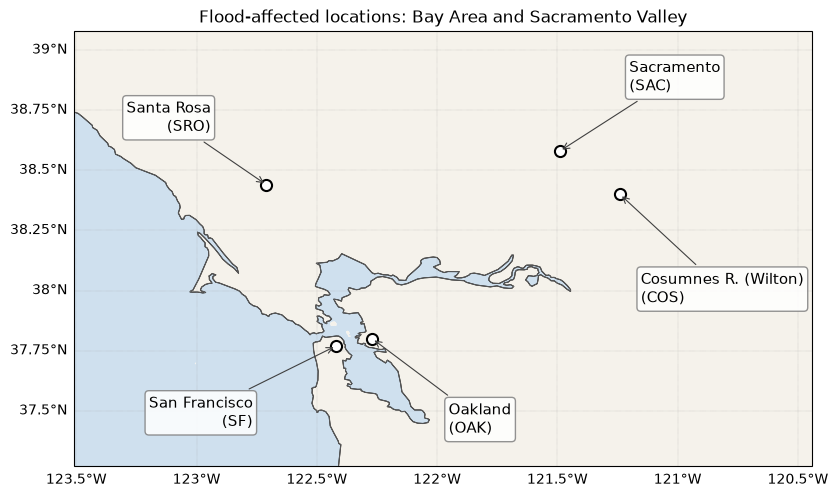

In [7]:
# Hand-placed label offsets (points from each marker) so the Bay Area names never overlap.
LABEL_OFFSETS = {
    "San Francisco":        (-60, -35),
    "Oakland":              (55, -45),
    "Santa Rosa":           (-40, 35),
    "Sacramento":           (50, 40),
    "Cosumnes R. (Wilton)": (15, -55),
}

margin_lon, margin_lat = 0.8, 0.5  # degrees of map around the outermost locations (wider east-west, for the labels)
loc_lats = [lat for lat, _ in LOCATIONS.values()]
loc_lons = [lon for _, lon in LOCATIONS.values()]
loc_extent = [min(loc_lons) - margin_lon, max(loc_lons) + margin_lon, min(loc_lats) - margin_lat, max(loc_lats) + margin_lat]

fig, ax = plt.subplots(figsize=(8.5, 6.5), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent(loc_extent, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#cfe0ee")
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#f5f2eb")
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), lw=0.8)
ax.add_feature(cfeature.STATES.with_scale("10m"), lw=0.6, edgecolor="0.4")
gl = ax.gridlines(draw_labels=True, lw=0.3, color="0.6", ls=":")
gl.top_labels = gl.right_labels = False
for name, (lat, lon) in LOCATIONS.items():
    dx, dy = LABEL_OFFSETS.get(name, (40, 30))
    ax.plot(lon, lat, marker="o", ms=8, mfc="white", mec="k", mew=1.5, transform=ccrs.PlateCarree(), zorder=5)
    # These axes use PlateCarree, so "data" coordinates are lon/lat in degrees.
    ax.annotate(f"{name}\n({SHORT[name]})", xy=(lon, lat), xycoords="data",
                xytext=(dx, dy), textcoords="offset points",
                ha="right" if dx < 0 else "left", va="top" if dy < 0 else "bottom", fontsize=11,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.5", alpha=0.85),
                arrowprops=dict(arrowstyle="->", color="0.25", lw=0.8), zorder=6)
ax.set_title("Flood-affected locations: Bay Area and Sacramento Valley", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "flood_locations.png", dpi=110, bbox_inches="tight")
plt.show()

### Event totals by lead time

Rows are the three lead times, and columns are the **forecast** (SFNO + PrecipitationAFNO v2, named in the figure title), **ERA5 truth**, and **Forecast − ERA5**. Look at how the forecast panel and the difference panel change as the lead time shrinks from 10 to 3 days.

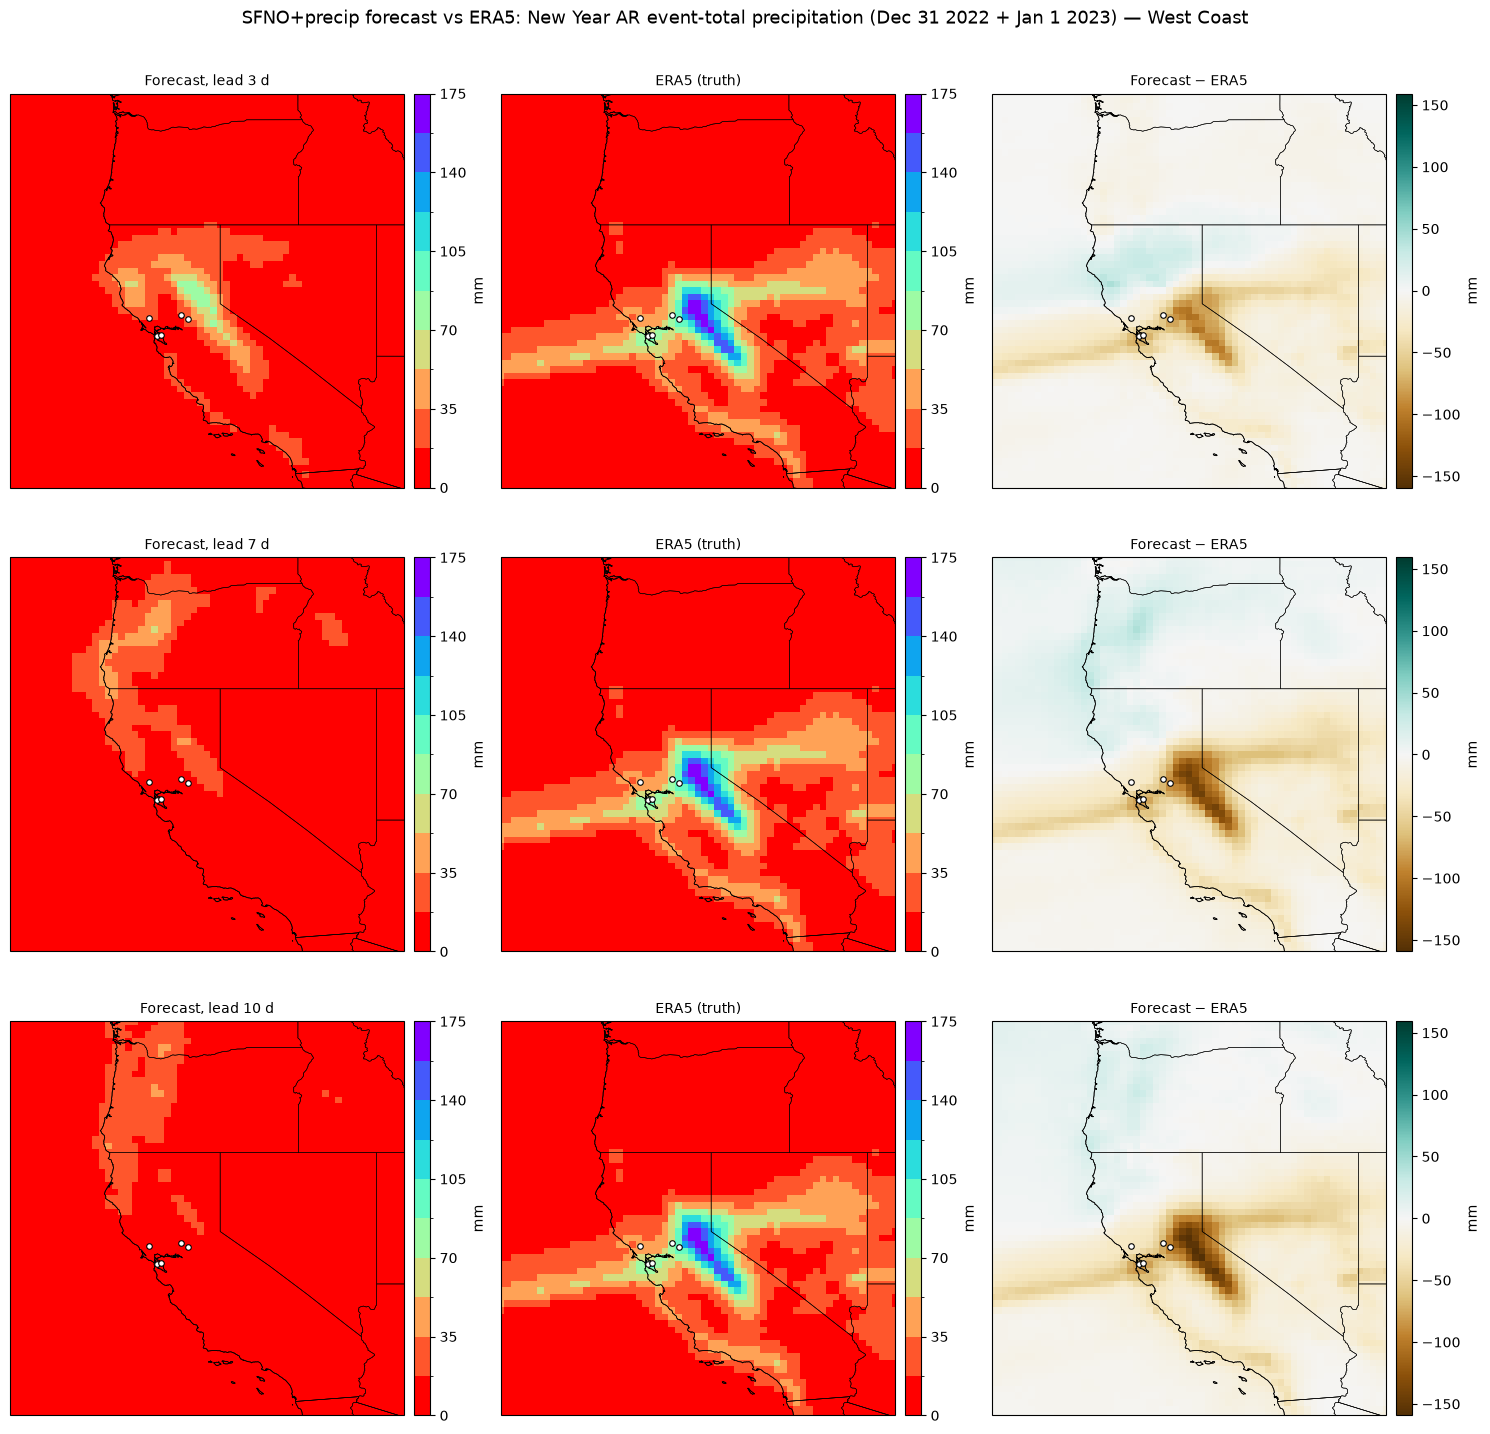

In [8]:
def event_total(field):
    '''Sum daily-total precip over the event days (robust to datetime resolution).'''
    days = field["day"].values.astype("datetime64[D]")
    sel = np.isin(days, EVENT_DAYS.astype("datetime64[D]"))
    return field.isel(day=np.where(sel)[0]).sum("day")

ev_fc = {L: to_180(event_total(fc_wc[L])) for L in LEAD_DAYS}
ev_era5 = {L: to_180(event_total(era5_wc[L])) for L in LEAD_DAYS}

# One shared color range for every precipitation panel: the largest event total, rounded up to 25 mm.
vmax = 25 * np.ceil(max(float(max(ev_fc[L].max(), ev_era5[L].max())) for L in LEAD_DAYS) / 25) or 25
precip_norm = BoundaryNorm(np.linspace(0, vmax, 11), PRECIP_CMAP.N)
dmax = max(float(np.nanmax(np.abs((ev_fc[L] - ev_era5[L]).values))) for L in LEAD_DAYS) or 1.0
info = REGIONS["WEST_COAST"]

fig, axes = plt.subplots(len(LEAD_DAYS), 3, figsize=(15, 4.8 * len(LEAD_DAYS)),
                         subplot_kw={"projection": ccrs.PlateCarree()})
for r, L in enumerate(LEAD_DAYS):
    a, e = ev_fc[L], ev_era5[L]
    diff = a - e
    panels = [(f"Forecast, lead {L} d", a, PRECIP_CMAP, dict(norm=precip_norm)),
              ("ERA5 (truth)", e, PRECIP_CMAP, dict(norm=precip_norm)),
              ("Forecast − ERA5", diff, "BrBG", dict(vmin=-dmax, vmax=dmax))]
    for c, (title, fld, cmap, scale) in enumerate(panels):
        ax = axes[r, c]
        m = ax.pcolormesh(fld["lon"], fld["lat"], fld, cmap=cmap, shading="auto",
                          transform=ccrs.PlateCarree(), **scale)
        ax.set_extent([*info["lon180"], *info["lat"]], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, lw=0.6)
        ax.add_feature(cfeature.BORDERS, lw=0.4)
        ax.add_feature(cfeature.STATES, lw=0.4)
        # mark the five locations with small hollow-looking markers and no text: the Bay Area cities are
        # too close together to label here (names: locator map above and section 7)
        for plat, plon in LOCATIONS.values():
            ax.plot(plon, plat, marker="o", ms=4, mfc="white", mec="k", mew=0.8,
                    transform=ccrs.PlateCarree())
        ax.set_title(title, fontsize=10)
        map_colorbar(fig, ax, m, label="mm")
fig.suptitle(f"{FC_LABEL} forecast vs ERA5: New Year AR event-total precipitation (Dec 31 2022 + Jan 1 2023) — West Coast",
             y=1.002, fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "precip_eventtotal_leadsweep.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read this.** Each row is one lead time, and the small white markers show the five flood locations (the locator map above and section 7 name them). The first two columns show the event-total precipitation (mm) from SFNO + PrecipitationAFNO v2 and from ERA5 on one shared color scale: red is little rain, blue-purple is a lot. The third column shows `Forecast − ERA5` on a diverging scale: brown means the model produced less rain than ERA5, green means more. Look for whether the heavy-rain band lands in the same place and with the same intensity as ERA5, and whether the difference panel fades as the lead time shrinks from 10 to 3 days. ERA5 precipitation is itself model-derived, so these panels show agreement with ERA5, not with rain-gauge totals.

## 6b · Skill by lead time

The maps compare patterns by eye; this table scores them. For each lead time it compares the SFNO + PrecipitationAFNO v2 event total (Dec 31 – Jan 1) with the ERA5 event total over the whole West Coast box, area-weighted, and saves the result to `docs/results/Flooding_metrics.csv` (the README embeds it). Bias, RMSE and MAE are in mm and bias is `SFNO+precip − ERA5`; pattern correlation compares the spatial shape of the two fields; "Total bias (%)" is the difference of the area-mean totals relative to ERA5. ERA5 precipitation is itself model-derived.

In [9]:
rows = []
for lead in LEAD_DAYS:
    fc_total, ref_total = event_total(fc_wc[lead]), event_total(era5_wc[lead])
    lats = fc_total["lat"].values
    rows.append({
        "Lead (days)": lead,
        **skill_row(fc_total.values, ref_total.values, lats),
        **event_total_error(fc_total.values, ref_total.values, lats),
    })
lead_skill = pd.DataFrame(rows)
lead_skill.to_csv(RESULTS_DIR / "Flooding_metrics.csv", index=False)
print("SFNO + PrecipitationAFNO v2 event-total precipitation (Dec 31 - Jan 1) vs ERA5, West Coast box (mm)\n")
print(lead_skill.to_string(index=False))

SFNO + PrecipitationAFNO v2 event-total precipitation (Dec 31 - Jan 1) vs ERA5, West Coast box (mm)

 Lead (days)    Bias   RMSE    MAE  Pattern corr  Forecast area-mean  Reference area-mean  Total bias (%)
           3  -9.319 19.176 12.098         0.658                 7.4                 16.7           -55.9
           7 -10.642 25.575 16.855        -0.022                 6.0                 16.7           -63.8
          10 -12.431 26.649 16.738        -0.157                 4.2                 16.7           -74.6


**How to read this.** One row per lead time. A bias or total bias close to 0 means the forecast's box-average rainfall matches ERA5; RMSE and MAE measure the grid-cell errors in mm (smaller is better); a pattern correlation near 1 means the rain falls in the right places even if the amounts are off. Compare the rows to see how the scores change as the lead time grows from 3 to 10 days.

## 7 · Event-total precipitation by location and lead time

Total precipitation for the event (Dec 31 2022 + Jan 1 2023) at each location's **exact grid cell**,
comparing ERA5 truth with the SFNO + PrecipitationAFNO v2 forecast at 3 / 7 / 10-day lead — as a table (with the
SFNO+precip − ERA5 bias per lead) and a grouped bar chart. This is the headline: *did the forecast capture the rain
where it actually flooded, and how far ahead?*

Event-total precip (Dec 31 + Jan 1), exact grid cell, mm:


,ERA5,SFNO+precip 3d,bias 3d,SFNO+precip 7d,bias 7d,SFNO+precip 10d,bias 10d
location,,,,,,,
SF,85.8,12.4,-73.4,6.7,-79.1,2.7,-83.1
SAC,74.3,15.5,-58.8,7.9,-66.4,1.8,-72.5
OAK,89.7,9.9,-79.8,4.8,-84.9,1.3,-88.4
SRO,36.8,18.3,-18.5,11.8,-25.0,4.5,-32.3
COS,98.1,23.1,-75.0,10.3,-87.8,2.9,-95.2


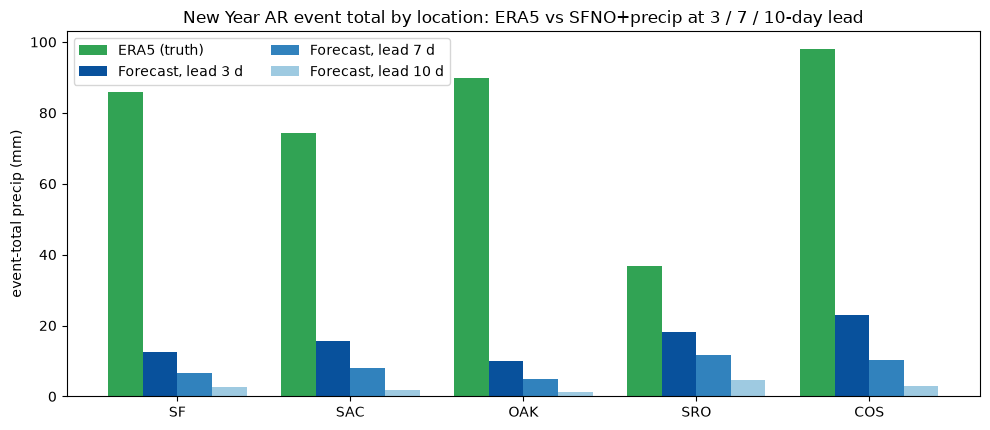

In [10]:
def event_total_at(field, lat, lon):
    '''EXACT-cell event total (Dec 31 + Jan 1) at a point, in mm. No averaging.'''
    s = at_point(field, lat, lon)
    days = s["day"].values.astype("datetime64[D]")
    sel = np.isin(days, EVENT_DAYS.astype("datetime64[D]"))
    return float(s.isel(day=np.where(sel)[0]).sum())

rows = {}
for name, (lat, lon) in LOCATIONS.items():
    era5 = round(event_total_at(era5_daily, lat, lon), 1)
    r = {"ERA5": era5}
    for L in LEAD_DAYS:
        a = round(event_total_at(fc_daily[L], lat, lon), 1)
        r[f"{FC_LABEL} {L}d"] = a
        r[f"bias {L}d"] = round(a - era5, 1)
    rows[SHORT[name]] = r
loc_event = pd.DataFrame(rows).T
loc_event.index.name = "location"
print("Event-total precip (Dec 31 + Jan 1), exact grid cell, mm:")
display(loc_event)

# grouped bar chart: ERA5 truth + the forecast at each lead, per location
labels = list(loc_event.index)
x = np.arange(len(labels))
w = 0.2
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - 1.5 * w, loc_event["ERA5"],     w, label="ERA5 (truth)", color="#31a354")
ax.bar(x - 0.5 * w, loc_event[f"{FC_LABEL} 3d"],  w, label="Forecast, lead 3 d",  color="#08519c")
ax.bar(x + 0.5 * w, loc_event[f"{FC_LABEL} 7d"],  w, label="Forecast, lead 7 d",  color="#3182bd")
ax.bar(x + 1.5 * w, loc_event[f"{FC_LABEL} 10d"], w, label="Forecast, lead 10 d", color="#9ecae1")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("event-total precip (mm)")
ax.set_title(f"New Year AR event total by location: ERA5 vs {FC_LABEL} at 3 / 7 / 10-day lead")
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "precip_eventtotal_by_location.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read this.** In the table, each row is a location: `ERA5` is the event total at that grid cell, `SFNO+precip Nd` is the forecast at N days of lead, and `bias Nd` is `SFNO+precip − ERA5` (positive means the model rained more than ERA5). In the bar chart, the green bar is ERA5 and the blue bars are the forecasts, darkest for the shortest lead. Look for locations where the bars at short lead match ERA5 and for the lead time at which they stop doing so. Values are single 0.25° grid cells, so they are not rain-gauge totals.

## Summary

- **Per-day tables (§5):** how much rain each location received on each day in the SFNO + PrecipitationAFNO v2 forecast and in ERA5, and how the event-total row compares.
- **Locator map (§6):** where the five flood locations sit around San Francisco Bay and the Sacramento Valley, named once so that the map grid can leave the rain visible.
- **Event-total maps (§6):** whether the heavy-rain band of the atmospheric river lands in the right place at 10, 7 and 3 days of lead time, and where the model over- or under-forecasts.
- **Skill by lead time (§6b):** area-weighted bias, RMSE, MAE, pattern correlation and total bias of the event-total precipitation over the West Coast box, one row per lead time.
- **Event totals by location (§7):** whether the forecast captured the rain where it actually flooded, and how far ahead.

All comparisons are against ERA5 precipitation, which is itself model-derived rather than gauge or radar data. The numbers change with every run, so they live in the tables above and in the CSV file `docs/results/Flooding_metrics.csv`, not in this text.